# **Upload Datasets**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
!unzip "/content/drive/MyDrive/Derma_detection/Whole Picture Detection/new_classes_aug_datasets(45-90-180).zip"

In [ ]:
import shutil
import os 
from tqdm import tqdm 
from glob import glob 

In [ ]:
print(len(os.listdir("/content/drive/MyDrive/Derma_detection/Whole Picture Detection/new_images")))

1036


# **Augmentation**


In [ ]:
from distutils.dir_util import copy_tree

copy_tree("/content/drive/MyDrive/Derma_detection/Whole Picture Detection/new_annotations","/content/new_folder/")
copy_tree("/content/drive/MyDrive/Derma_detection/Whole Picture Detection/new_images","/content/new_folder/")

In [ ]:
# Importing Libraries
import os
import numpy as np
import cv2
import argparse
import time
from tqdm import tqdm
#convert from Yolo_mark to opencv format
def yoloFormattocv(x1, y1, x2, y2, H, W):
    bbox_width = x2 * W
    bbox_height = y2 * H
    center_x = x1 * W
    center_y = y1 * H
    voc = []
    voc.append(center_x - (bbox_width / 2))
    voc.append(center_y - (bbox_height / 2))
    voc.append(center_x + (bbox_width / 2))
    voc.append(center_y + (bbox_height / 2))
    return [int(v) for v in voc]

In [ ]:
# Convert from opencv format to yolo format
# H,W is the image height and width
def cvFormattoYolo(corner, H, W):
    bbox_W = corner[3] - corner[1]
    bbox_H = corner[4] - corner[2]
    center_bbox_x = (corner[1] + corner[3]) / 2
    center_bbox_y = (corner[2] + corner[4]) / 2
    return corner[0], round(center_bbox_x / W, 6),round(center_bbox_y / H, 6),round(bbox_W / W, 6), round(bbox_H / H, 6)

In [ ]:
class yoloRotatebbox:
    def __init__(self,path, image_name, image_ext, angle):

        assert os.path.isfile(path + "/" + image_name + image_ext)
        assert os.path.isfile(path + "/" + image_name + '.txt')
        
        self.image_name = image_name
        self.image_ext = image_ext
        self.angle = angle
        
        # Read image using cv2
        self.image = cv2.imread(path + "/" + self.image_name + self.image_ext, 1)
        
        rotation_angle = self.angle * np.pi / 180
        self.rot_matrix = np.array(
            [[np.cos(rotation_angle), -np.sin(rotation_angle)], [np.sin(rotation_angle), np.cos(rotation_angle)]])
    def rotateYolobbox(self):
        new_height, new_width = self.rotate_image().shape[:2]
        f = open(path + "/" + self.image_name + '.txt', 'r')
        f1 = f.readlines()
        new_bbox = []
        H, W = self.image.shape[:2]
        for x in f1:
            bbox = x.strip('\n').split(' ')
            if len(bbox) > 1:
                (center_x, center_y, bbox_width, bbox_height) = yoloFormattocv(float(bbox[1]), float(bbox[2]),
                                                                               float(bbox[3]), float(bbox[4]), H, W)
                upper_left_corner_shift = (center_x - W / 2, -H / 2 + center_y)
                upper_right_corner_shift = (bbox_width - W / 2, -H / 2 + center_y)
                lower_left_corner_shift = (center_x - W / 2, -H / 2 + bbox_height)
                lower_right_corner_shift = (bbox_width - W / 2, -H / 2 + bbox_height)
                new_lower_right_corner = [-1, -1]
                new_upper_left_corner = []
                for i in (upper_left_corner_shift, upper_right_corner_shift, lower_left_corner_shift,
                          lower_right_corner_shift):
                    new_coords = np.matmul(self.rot_matrix, np.array((i[0], -i[1])))
                    x_prime, y_prime = new_width / 2 + new_coords[0], new_height / 2 - new_coords[1]
                    if new_lower_right_corner[0] < x_prime:
                        new_lower_right_corner[0] = x_prime
                    if new_lower_right_corner[1] < y_prime:
                        new_lower_right_corner[1] = y_prime
                    if len(new_upper_left_corner) > 0:
                        if new_upper_left_corner[0] > x_prime:
                            new_upper_left_corner[0] = x_prime
                        if new_upper_left_corner[1] > y_prime:
                            new_upper_left_corner[1] = y_prime
                    else:
                        new_upper_left_corner.append(x_prime)
                        new_upper_left_corner.append(y_prime)
                #             print(x_prime, y_prime)
                new_bbox.append([bbox[0], new_upper_left_corner[0], new_upper_left_corner[1],
                                 new_lower_right_corner[0], new_lower_right_corner[1]])
        return new_bbox
    def rotate_image(self):
        """
        Rotates an image (angle in degrees) and expands image to avoid cropping
        """
        height, width = self.image.shape[:2]  # image shape has 3 dimensions
        image_center = (width / 2,
                        height / 2)  # getRotationMatrix2D needs coordinates in reverse order (width, height) compared to shape
        rotation_mat = cv2.getRotationMatrix2D(image_center, self.angle, 1.)
        # rotation calculates the cos and sin, taking absolutes of those.
        abs_cos = abs(rotation_mat[0, 0])
        abs_sin = abs(rotation_mat[0, 1])
        # find the new width and height bounds
        bound_w = int(height * abs_sin + width * abs_cos)
        bound_h = int(height * abs_cos + width * abs_sin)
        # subtract old image center (bringing image back to origin) and adding the new image center coordinates
        rotation_mat[0, 2] += bound_w / 2 - image_center[0]
        rotation_mat[1, 2] += bound_h / 2 - image_center[1]
        # rotate image with the new bounds and translated rotation matrix
        rotated_mat = cv2.warpAffine(self.image, rotation_mat, (bound_w, bound_h))
        return rotated_mat

In [ ]:
if __name__ == "__main__":
  
    angels=[45,90,180]
    path = "/content/new_folder"
    os.makedirs(path + "_aug")

    for filename in tqdm(os.listdir(path)):
        file =filename.split(".")
        if(file[-1]=="jpg"):
            image_name=file[0]
            image_ext="."+file[1]
            print(image_name)
            print(image_ext)
        else:
            continue
        
        for angle in angels:

          try:
            im = yoloRotatebbox(path,image_name, image_ext, angle)
            bbox = im.rotateYolobbox()
            image = im.rotate_image()
            # to write rotateed image to disk
            cv2.imwrite(path + "_aug/" + image_name+'_' + str(angle) + '.jpg', image)
            file_name = path + "_aug/" + image_name+'_' + str(angle) + '.txt'
            #print("For angle "+str(angle))
            if os.path.exists(file_name):
                os.remove(file_name)
            # to write the new rotated bboxes to file
            for i in bbox:
                with open(file_name, 'a') as fout:
                    fout.writelines(
                        ' '.join(map(str, cvFormattoYolo(i, im.rotate_image().shape[0], im.rotate_image().shape[1]))) + '\n')
                    
          except AssertionError as e:
            print("AssertionError")

# **Data Process**

In [ ]:
data_images_path = "/content/drive/MyDrive/Derma_detection/Whole Picture Detection/new_images"   
data_labels_path = "/content/drive/MyDrive/Derma_detection/Whole Picture Detection/new_annotations"

In [ ]:
from glob import glob 
trainimages = glob(data_images_path +"/*.jpg")
trainlabels = glob(data_labels_path +"/*.txt")
print(len(trainimages))
print(len(trainlabels))


In [ ]:
# for augmentation dataset 

data_augmentation_path = "/content/new_folder_aug"

trainimages = glob(data_augmentation_path +"/*.jpg")
trainlabels = glob(data_augmentation_path +"/*.txt")
print(len(trainimages))
print(len(trainlabels))

3087
3021


In [ ]:
import os 

os.mkdir("/content/datasets")
os.mkdir("/content/datasets/images")
os.mkdir("/content/datasets/labels")

os.mkdir("/content/datasets/images/train")
os.mkdir("/content/datasets/images/test")
os.mkdir("/content/datasets/images/valid")


os.mkdir("/content/datasets/labels/train")
os.mkdir("/content/datasets/labels/test")
os.mkdir("/content/datasets/labels/valid")


dataset_train_path = "/content/datasets/images/train"
dataset_valid_path ="/content/datasets/images/valid"
dataset_test_path = "/content/datasets/images/test"




In [ ]:
from sklearn.model_selection import train_test_split
train_image, test_image= train_test_split(trainimages,shuffle=True, test_size=0.25, random_state=42)
print("train count",len(train_image))
print("valid count",len(test_image))


train count 2315
valid count 772


In [ ]:
train_image, valid_image= train_test_split(train_image,shuffle=True, test_size=0.2, random_state=42)
print("train count",len(train_image))
print("test count",len(valid_image))

train count 1852
test count 463


In [ ]:
print(len(train_image))
print(len(test_image))
print(len(valid_image))

1852
772
463


In [ ]:
import shutil
for train in train_image:
  shutil.copy(train,dataset_train_path)

for valid in valid_image:
  shutil.copy(valid,dataset_valid_path)

for test in test_image:
  shutil.copy(test,dataset_test_path)


In [ ]:
datasetrain = glob(dataset_train_path +"/*.jpg")
datasetvalid = glob(dataset_valid_path + "/*.jpg")
datasettest = glob(dataset_test_path + "/*.jpg")
print(len(datasetrain))
print(len(datasetvalid))
print(len(datasettest))

1852
463
772


In [ ]:
import shutil

trainlabels = glob(data_augmentation_path +"/*.txt")
for labels in trainlabels:
  for trainlabels in datasetrain:
    if(labels.split("/")[3].split(".txt")[0] == trainlabels.split("/")[5].split(".jpg")[0]):
      shutil.copy(labels,"/content/datasets/labels/train")

trainlabels = glob(data_augmentation_path +"/*.txt")
for labels in trainlabels:
  for testlabels in datasettest:
    if(labels.split("/")[3].split(".txt")[0] == testlabels.split("/")[5].split(".jpg")[0]):
      shutil.copy(labels,"/content/datasets/labels/test")

trainlabels = glob(data_augmentation_path +"/*.txt")
for labels in trainlabels:
  for validlabels in datasetvalid:
    if(labels.split("/")[3].split(".txt")[0] == validlabels.split("/")[5].split(".jpg")[0]):
      shutil.copy(labels,"/content/datasets/labels/valid")

In [ ]:
import os 
print(len(os.listdir("/content/datasets/images/test"))) , print(len(os.listdir("/content/datasets/labels/test")))
print(len(os.listdir("/content/datasets/images/train"))) , print(len(os.listdir("/content/datasets/labels/train")))
print(len(os.listdir("/content/datasets/images/valid"))) , print(len(os.listdir("/content/datasets/labels/valid")))






In [ ]:
!zip -r "/content/drive/MyDrive/Derma_detection/Whole Picture Detection/new_classes_aug_datasets(45-90-180)" "/content/datasets"

# **Yolo v5**

In [ ]:
!git clone https://github.com/ultralytics/yolov5  # clone
%cd yolov5
%pip install -qr requirements.txt  # install

import torch
import utils
display = utils.notebook_init()  # checks

Setup complete ✅ (2 CPUs, 12.7 GB RAM, 45.3/78.2 GB disk)


In [ ]:
numberclass = 11
class_name = ["micro-rubrum","macro-rubrum","macro-gypseum","micro-interdigitale","macro-interdigitale","macro-canis","pektinat-audouinii","klamidor-audouinii","klamidor-tonsurans","micro-tonsurans","macro-tonsurans"]

In [ ]:
import yaml

data = dict(
    nc = numberclass,
    names = class_name,
    path = '/content/datasets',
    train = 'images/train',
    val = 'images/valid',
    test = 'images/test',
    
    )


with open('/content/yolov5/data/data.yaml', 'w') as outfile:
    yaml.dump(data, outfile, default_flow_style=False)



# **Training**

In [ ]:
!python train.py --img 512 --batch 16 --workers 4 --epochs 150 --data data.yaml --weights yolov5x.pt --cache

In [ ]:
from distutils.dir_util import copy_tree
copy_tree("/content/yolov5/runs","/content/drive/MyDrive/Derma_detection/Whole Picture Detection/results/new_classes_aug(45-90-180)") #/content/drive/MyDrive/runss     /content/yolov5/runs

['/content/drive/MyDrive/Derma_detection/Whole Picture Detection/results/new_classes_aug(45-90-180)/train/exp/confusion_matrix.png',
 '/content/drive/MyDrive/Derma_detection/Whole Picture Detection/results/new_classes_aug(45-90-180)/train/exp/val_batch0_pred.jpg',
 '/content/drive/MyDrive/Derma_detection/Whole Picture Detection/results/new_classes_aug(45-90-180)/train/exp/val_batch1_pred.jpg',
 '/content/drive/MyDrive/Derma_detection/Whole Picture Detection/results/new_classes_aug(45-90-180)/train/exp/weights/best.pt',
 '/content/drive/MyDrive/Derma_detection/Whole Picture Detection/results/new_classes_aug(45-90-180)/train/exp/weights/last.pt',
 '/content/drive/MyDrive/Derma_detection/Whole Picture Detection/results/new_classes_aug(45-90-180)/train/exp/results.csv',
 '/content/drive/MyDrive/Derma_detection/Whole Picture Detection/results/new_classes_aug(45-90-180)/train/exp/opt.yaml',
 '/content/drive/MyDrive/Derma_detection/Whole Picture Detection/results/new_classes_aug(45-90-180)/tr

In [ ]:
# Tensorboard  (optional)
%load_ext tensorboard
%tensorboard --logdir runs/train

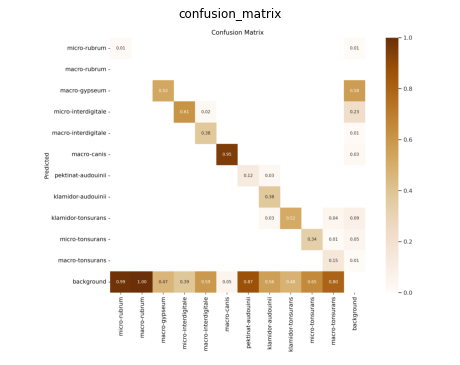

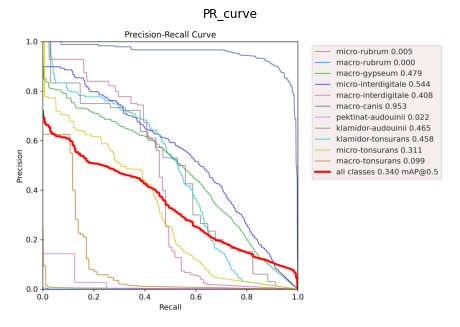

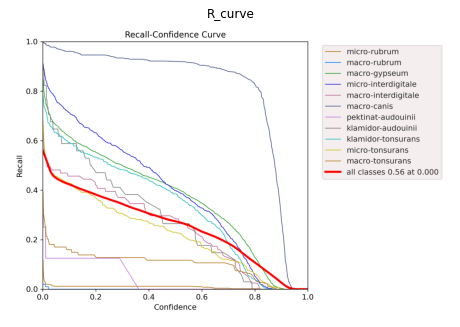

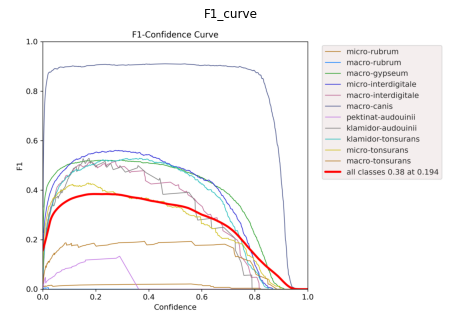

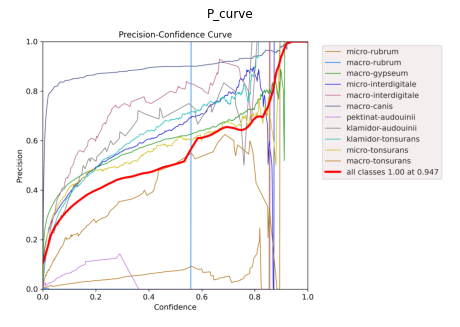

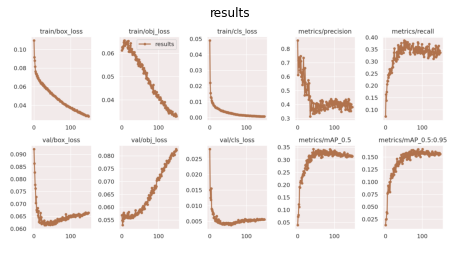

In [ ]:
import matplotlib.pyplot as plt
import cv2
from glob import glob
pnglist = glob("/content/yolov5/runs/train/exp/*.png")


for img in pnglist:
  imagename = img.split("/")[6].split(".png")[0]
  
  pngimage = cv2.imread(img)
  
  plt.figure(figsize = (8,8))
  plt.axis("off")
  plt.title(imagename)
  plt.imshow(pngimage)

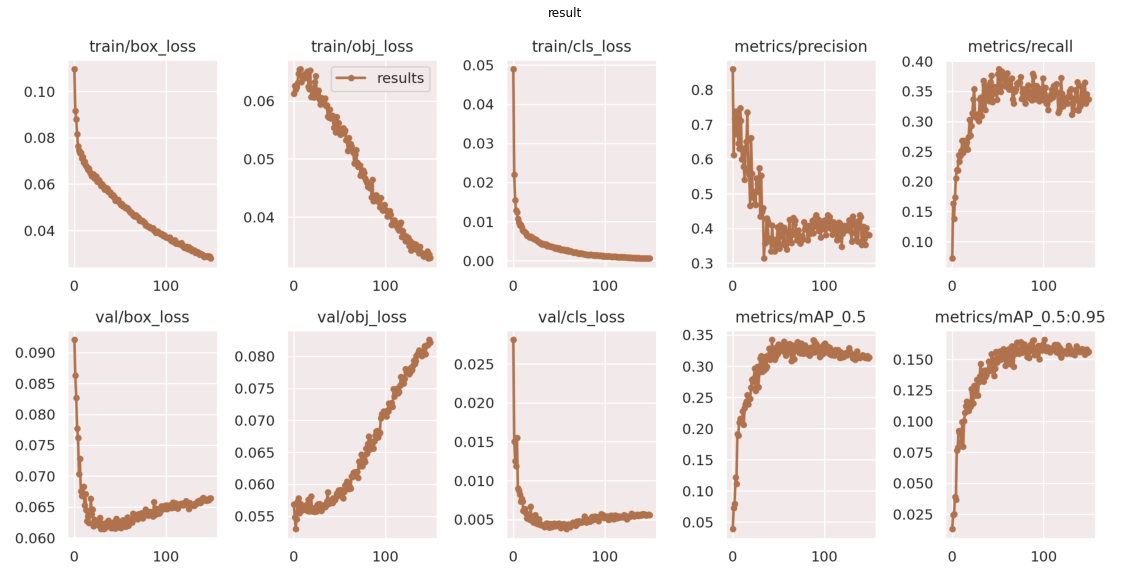

In [ ]:
result = cv2.imread("/content/yolov5/runs/train/exp/results.png")
plt.figure(figsize = (20,20))
plt.axis("off")
plt.title("result")
plt.imshow(result)


In [ ]:
pnglist = glob("/content/yolov5/runs/train/exp/*.jpg")


for img in pnglist:
  imagename = img.split("/")[6].split(".jpg")[0]
  
  pngimage = cv2.imread(img)
  pngimage = cv2.cvtColor(pngimage,cv2.COLOR_BGR2RGB)
  plt.figure(figsize = (8,8))
  plt.axis("off")
  plt.title(imagename)
  plt.imshow(pngimage)

# **Testing**

In [ ]:
import shutil
bestweights = "/content/yolov5/runs/train/exp/weights/best.pt"
lastweights = "/content/yolov5/runs/train/exp/weights/last.pt"
shutil.copy(bestweights,"/content/yolov5")
shutil.copy(lastweights,"/content/yolov5")

'/content/yolov5/last.pt'

In [ ]:
!python val.py --weights best.pt --data data.yaml --img 512 --iou 0.5 --save-hybrid --dnn --half --task test

In [ ]:
copy_tree("/content/yolov5/runs","/content/drive/MyDrive/Derma_detection/Whole Picture Detection/results/new_classes_aug(45-90-180)")

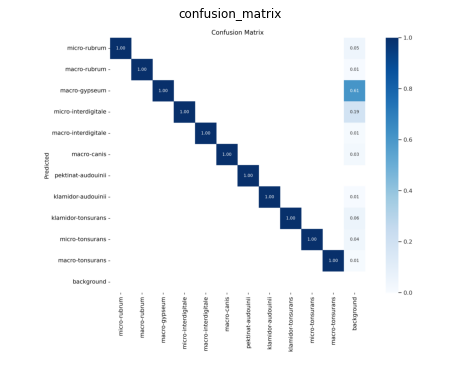

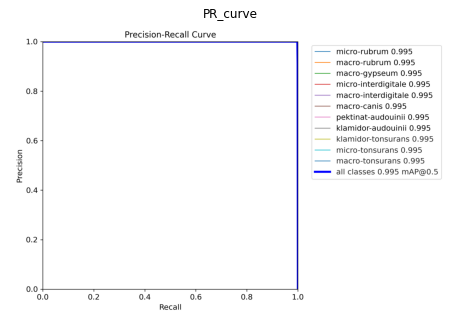

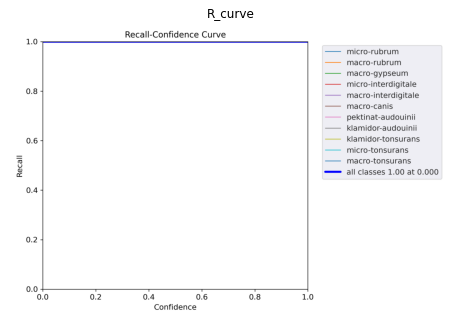

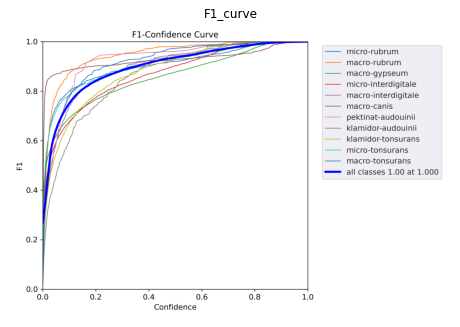

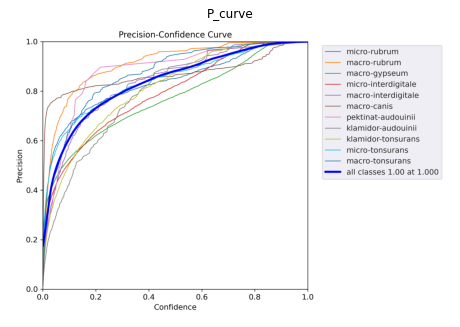

In [ ]:
pnglist = glob("/content/yolov5/runs/val/exp/*.png")


for img in pnglist:
  imagename = img.split("/")[6].split(".png")[0]
  
  pngimage = cv2.imread(img)
  pngimage = cv2.cvtColor(pngimage,cv2.COLOR_BGR2RGB)
  plt.figure(figsize = (8,8))
  plt.axis("off")
  plt.title(imagename)
  plt.imshow(pngimage)


In [ ]:
pnglist = glob("/content/yolov5/runs/val/exp/*.jpg")


for img in pnglist:
  imagename = img.split("/")[6].split(".jpg")[0]
  
  pngimage = cv2.imread(img)
  pngimage = cv2.cvtColor(pngimage,cv2.COLOR_BGR2RGB)
  plt.figure(figsize = (8,8))
  plt.axis("off")
  plt.title(imagename)
  plt.imshow(pngimage)


In [ ]:
!python detect.py --weights best.pt --img 512 --conf 0.6 --iou-thres 0.7 --save-txt --source /content/datasets/images/test

In [ ]:
import random
pnglist = glob("/content/yolov5/runs/detect/exp/*.jpg")


for img in random.sample(pnglist,20):
  imagename = img.split("/")[6].split(".jpg")[0]
  
  pngimage = cv2.imread(img)
  pngimage = cv2.cvtColor(pngimage,cv2.COLOR_BGR2RGB)
  plt.figure(figsize = (8,8))
  plt.axis("off")
  plt.title(imagename)
  plt.imshow(pngimage)


In [ ]:
copy_tree("/content/yolov5/runs","/content/drive/MyDrive/Derma_detection/Whole Picture Detection/results/new_classes_aug(45-90-180)")

In [ ]:
def yolo_to_pascal(bbox, w, h):
   
    w_half_len = (bbox[2] * w) / 2
    h_half_len = (bbox[3] * h) / 2
    xmin = int((bbox[0] * w) - w_half_len)
    ymin = int((bbox[1] * h) - h_half_len)
    xmax = int((bbox[0] * w) + w_half_len)
    ymax = int((bbox[1] * h) + h_half_len)
    return [xmin, ymin, xmax, ymax]

In [ ]:
size = 512

import imageio
jpeg_list = glob("/content/datasets/images/test/*.jpg")  # glob("/content/datasets/images/test/*.jpg")


for i in  random.sample(jpeg_list,20):  #random.sample(jpeg_list,20)
  img = imageio.imread(i)
  img = cv2.resize(img,(size,size))
  id_jpeg = i.split("/")[5].split(".jpg")[0]
  
     
  txt_file = "/content/datasets/labels/test/" + id_jpeg +".txt" #"/content/datasets/labels/test/" + id_jpeg +".txt"

  with open(txt_file,'r') as f:
    img_anns = f.readlines()
  try:
    for index in img_anns:
      x = float(index.split(" ")[1])
      y = float(index.split(" ")[2])
      h = float(index.split(" ")[3])
      w = float(index.split(" ")[4])
      bbox = [x,y,h,w]

      x1,y1,x2,y2 = yolo_to_pascal(bbox,size,size)
      cv2.rectangle(img,(x1,y1),(x2,y2),(0,0,255), 2)

      predict_txt = "/content/yolov5/runs/detect/exp/labels/" + id_jpeg + ".txt" #"/content/yolov5/runs/detect/exp/labels/" + id_jpeg + ".txt"

      with open(predict_txt,'r') as f:
          predictlines = f.readlines()
      for index in predictlines:
        # print(i.split(" "))
        classnumber = index.split(" ")[0]
        xp = float(index.split(" ")[1])
        yp = float(index.split(" ")[2])
        hp = float(index.split(" ")[3])
        wp = float(index.split(" ")[4])
        bboxp = [xp,yp,hp,wp]
        xp1,yp1,xp2,yp2 = yolo_to_pascal(bboxp,size,size)
        xA = max(x1, xp1)
        yA = max(y1, yp1)
        xB = min(x2, xp2)
        yB = min(y2, yp2)
        interArea = max(0, xB - xA + 1) * max(0, yB - yA + 1)
        boxAArea = (x2 - x1 + 1) * (y2 - y1 + 1)
        boxBArea = (xp2 - xp1 + 1) * (yp2 - yp1 + 1)
        iou = interArea / float(boxAArea + boxBArea - interArea)
        if(iou>0.5):
          cv2.rectangle(img,(xp1,yp1),(xp2,yp2),(255,0,0), 2)
          cv2.putText(img, " iou = {:.2f}".format(iou), (xp1,yp1-10), cv2.FONT_HERSHEY_SIMPLEX,0.5, (255,0,0),1, cv2.LINE_AA) 
          
  except FileNotFoundError as e:
    print("")   
 
  plt.figure(figsize = (10,10))
  plt.title(id_jpeg)   
  plt.axis("off")
  plt.imshow(img)

# **Appendix**

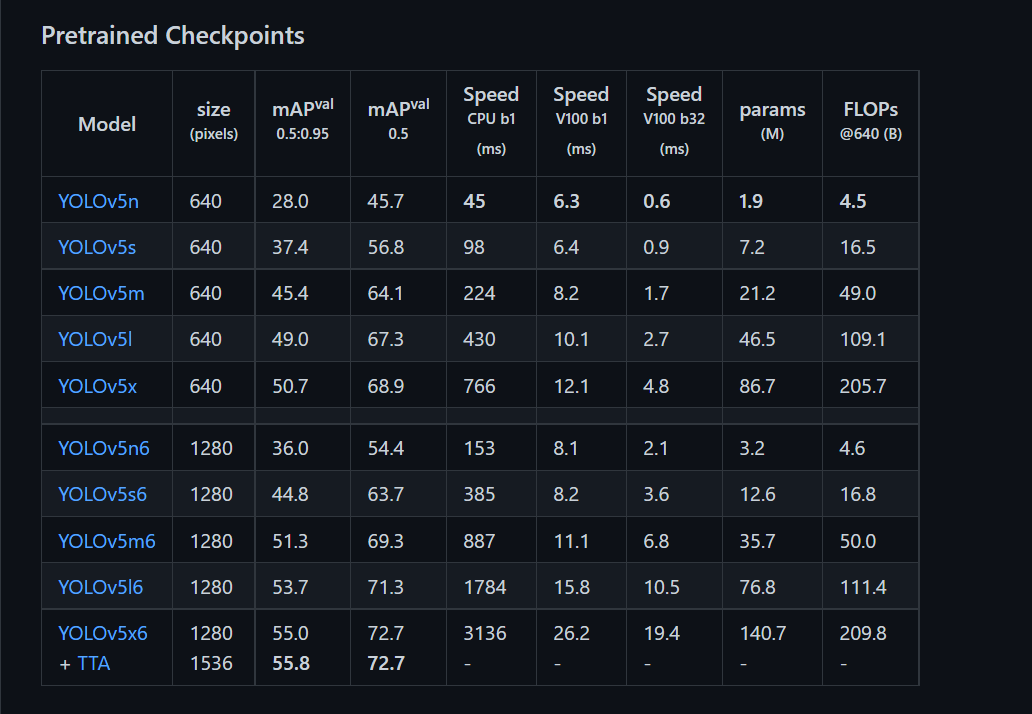

In [ ]:
# https://github.com/ultralytics/yolov5
for b, m in zip([64, 64, 64, 32, 16], ['yolov5n', 'yolov5s', 'yolov5m', 'yolov5l', 'yolov5x']):  # batch, model
  !python train.py --batch {b} --weights {m}.pt --data data.yaml --epochs 120 --img 512 --hyp hyp.VOC.yaml --project TRAINING --name {m} --cache

In [ ]:
# Reproduce
for x in 'yolov5n', 'yolov5s', 'yolov5m', 'yolov5l', 'yolov5x':
  !python val.py --weights {x}.pt --data coco.yaml --img 640 --task speed  # speed
  !python val.py --weights {x}.pt --data coco.yaml --img 640 --conf 0.001 --iou 0.65  # mAP

# SAHI 

In [ ]:
!pip install -U torch sahi yolov5

In [ ]:
import os
os.getcwd()

'/content/yolov5'

In [ ]:
from sahi.utils.cv import read_image
from sahi.utils.file import download_from_url
from sahi.predict import get_prediction, get_sliced_prediction, predict
from IPython.display import Image
from sahi.model import DetectionModel
from sahi.prediction import ObjectPrediction
from typing import Dict, List, Optional, Union
from sahi.utils.compatibility import fix_full_shape_list, fix_shift_amount_list

In [ ]:
CUSTOM_YOLO5_CLASS = True

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import sys
import cv2
import torch
from PIL import Image as Img
from IPython.display import display

In [ ]:
from IPython.core.magic import (register_line_cell_magic)

In [ ]:
# not neccessary 
import logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__) 

In [ ]:
class YourYolov5DetectionModel(DetectionModel):

  def load_model(self):

      try:
          import torch
      except ImportError:
          raise ImportError(
              "Please install torch and Your-YOLOv5 first for YOLOv5 inference."
          )

      # set model
      try:
          model = torch.hub.load("/content/yolov5", 
                        'custom', 
                        path=self.model_path,
                        source='local',
                        force_reload=True)
          model.conf = self.confidence_threshold
          self.model = model
      except Exception as e:
          TypeError("model_path is not a valid yolov5 model path: ", e)

      # set category_mapping
      if not self.category_mapping:
          category_mapping = {
              str(ind): category_name
              for ind, category_name in enumerate(self.category_names)
          }
          self.category_mapping = category_mapping

  def perform_inference(self, image: np.ndarray, image_size: int = None):
      """
      Prediction is performed using self.model and the prediction result is set to self._original_predictions.
      Args:
          image: np.ndarray
              A numpy array that contains the image to be predicted. 3 channel image should be in RGB order.
          image_size: int
              Inference input size.
      """
      try:
          import yolov5
      except ImportError:
          raise ImportError('Please run "pip install -U yolov5" ' "to install YOLOv5 first for YOLOv5 inference.")

      # Confirm model is loaded
      assert self.model is not None, "Model is not loaded, load it by calling .load_model()"

      if image_size is not None:
          warnings.warn("Set 'image_size' at DetectionModel init.", DeprecationWarning)
          prediction_result = self.model(image, size=image_size, augment=True)
      elif self.image_size is not None:
          prediction_result = self.model(image, size=self.image_size)
      else:
          prediction_result = self.model(image)

      self._original_predictions = prediction_result

  @property
  def num_categories(self):
      """
      Returns number of categories
      """
      return len(self.model.names)

  @property
  def has_mask(self):
      """
      Returns if model output contains segmentation mask
      """
      has_mask = self.model.with_mask
      return has_mask

  @property
  def category_names(self):
      return self.model.names

  def _create_object_prediction_list_from_original_predictions(
      self,
      shift_amount_list: Optional[List[List[int]]] = [[0, 0]],
      full_shape_list: Optional[List[List[int]]] = None,
  ):
      """
      self._original_predictions is converted to a list of prediction.ObjectPrediction and set to
      self._object_prediction_list_per_image.
      Args:
          shift_amount_list: list of list
              To shift the box and mask predictions from sliced image to full sized image, should
              be in the form of List[[shift_x, shift_y],[shift_x, shift_y],...]
          full_shape_list: list of list
              Size of the full image after shifting, should be in the form of
              List[[height, width],[height, width],...]
      """
      original_predictions = self._original_predictions

      # compatilibty for sahi v0.8.15
      shift_amount_list = fix_shift_amount_list(shift_amount_list)
      full_shape_list = fix_full_shape_list(full_shape_list)

      # handle all predictions
      object_prediction_list_per_image = []
      for image_ind, image_predictions_in_xyxy_format in enumerate(original_predictions.xyxy):
          shift_amount = shift_amount_list[image_ind]
          full_shape = None if full_shape_list is None else full_shape_list[image_ind]
          object_prediction_list = []

          # process predictions
          for prediction in image_predictions_in_xyxy_format.cpu().detach().numpy():
              x1 = int(prediction[0])
              y1 = int(prediction[1])
              x2 = int(prediction[2])
              y2 = int(prediction[3])
              bbox = [x1, y1, x2, y2]
              score = prediction[4]
              category_id = int(prediction[5])
              
              if category_id == 0:
                category_name = "canis"

              if category_id == 1:
                category_name = "rubrum"

              if category_id == 2:
                category_name = "tonsurans"

              # ignore invalid predictions
              if bbox[0] > bbox[2] or bbox[1] > bbox[3] or bbox[0] < 0 or bbox[1] < 0 or bbox[2] < 0 or bbox[3] < 0:
                  logger.warning(f"ignoring invalid prediction with bbox: {bbox}")
                  continue
              if full_shape is not None and (
                  bbox[1] > full_shape[0]
                  or bbox[3] > full_shape[0]
                  or bbox[0] > full_shape[1]
                  or bbox[2] > full_shape[1]
              ):
                  logger.warning(f"ignoring invalid prediction with bbox: {bbox}")
                  continue

              object_prediction = ObjectPrediction(
                  bbox=bbox,
                  category_id=category_id,
                  score=score,
                  bool_mask=None,
                  category_name=category_name,
                  shift_amount=shift_amount,
                  full_shape=full_shape,
              )
              object_prediction_list.append(object_prediction)
          object_prediction_list_per_image.append(object_prediction_list)

      self._object_prediction_list_per_image = object_prediction_list_per_image 

In [ ]:
detection_model = YourYolov5DetectionModel(
    
    model_path= "/content/yolov5/best.pt",
    confidence_threshold=0.5,
    device="cuda:0", # or 'cuda:0'
)

In [ ]:
SSfor path in random.sample((glob("/content/datasets/labels/test/*")),10):    
    
    result = get_sliced_prediction(
        path,
        detection_model,
        slice_height = 512,
        slice_width = 512,
        overlap_height_ratio = 0.2,
        overlap_width_ratio = 0.2
    )

    result.export_visuals(export_dir="demo_data/")

    Image("demo_data/prediction_visual.png")